In [4]:

!pip install pandas numpy matplotlib seaborn scikit-learn streamlit google-generativeai sqlalchemy pymysql plotly


In [6]:
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 9994
Total Columns: 21


In [8]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [9]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [10]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [11]:
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [12]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Ship Date'] = pd.to_datetime(df['Ship Date'])

print("Date columns converted successfully!")

Date columns converted successfully!


In [13]:
data_quality = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.values,
    'Missing Values': df.isnull().sum().values,
    'Unique Values': df.nunique().values
})

data_quality

,Column Name,Data Type,Missing Values,Unique Values
0,Row ID,int64,0,9994
1,Order ID,object,0,5009
2,Order Date,datetime64[ns],0,1237
3,Ship Date,datetime64[ns],0,1334
4,Ship Mode,object,0,4
5,Customer ID,object,0,793
6,Customer Name,object,0,793
7,Segment,object,0,3
8,Country,object,0,1
9,City,object,0,531


In [14]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793


In [15]:
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

print(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


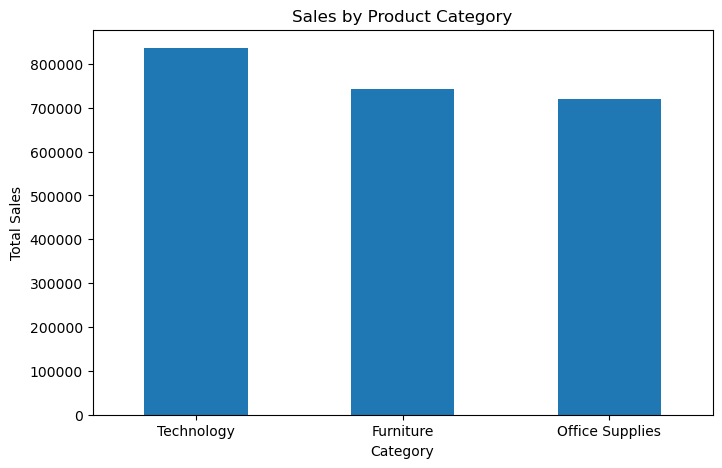

In [26]:
category_sales.plot(kind='bar', figsize=(8,5))

plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

In [19]:
top_products = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)

print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


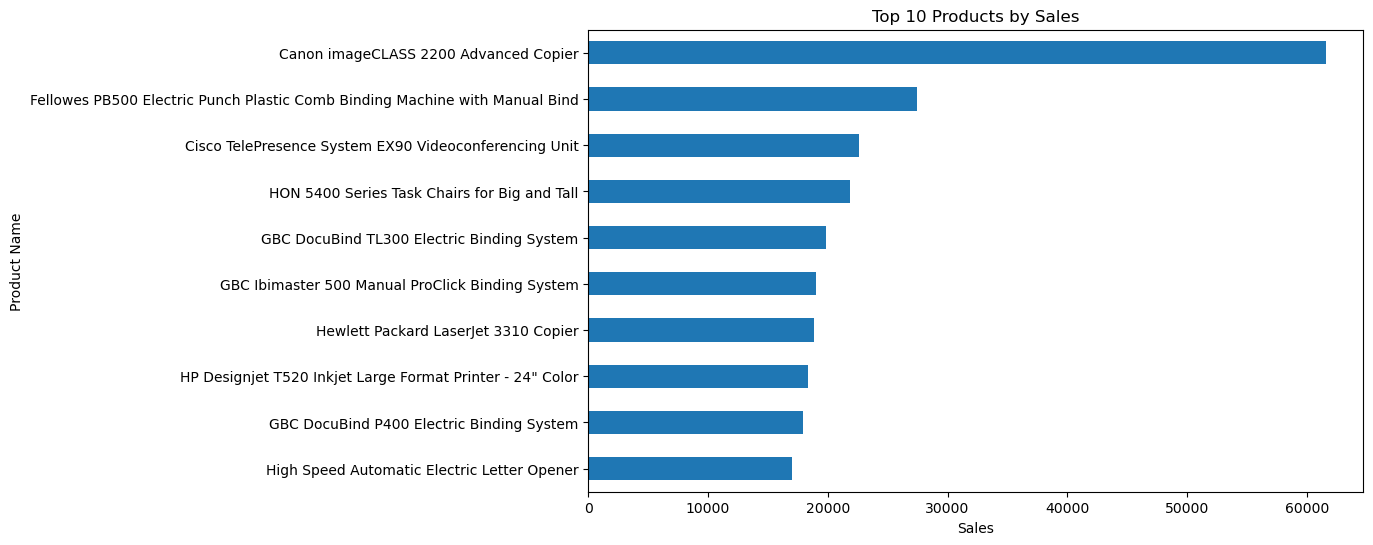

In [27]:
top_products.plot(kind='barh', figsize=(10,6))

plt.title('Top 10 Products by Sales')
plt.xlabel('Sales')
plt.ylabel('Product Name')
plt.gca().invert_yaxis()
plt.show()

In [21]:
region_profit = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)

print(region_profit)

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


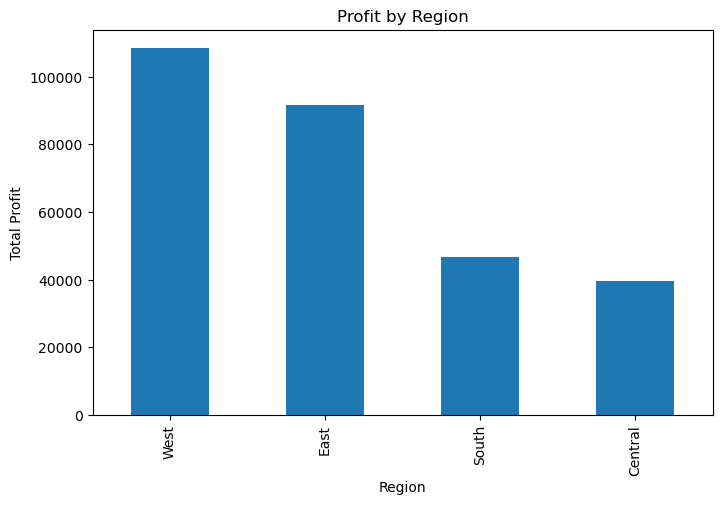

In [28]:
region_profit.plot(kind='bar', figsize=(8,5))

plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.show()

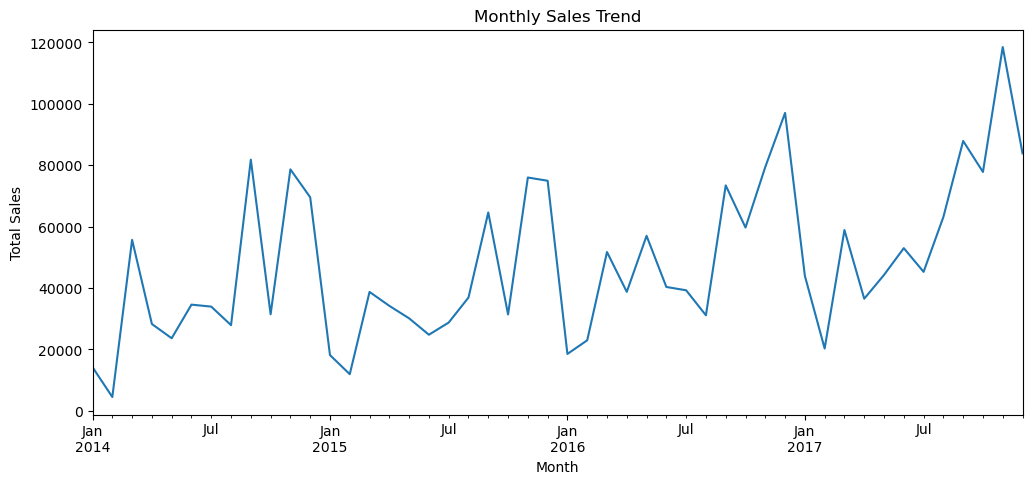

In [29]:
monthly_sales = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()

monthly_sales.plot(figsize=(12,5))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

In [24]:
customer_sales = df.groupby('Customer Name')['Sales'].sum().sort_values(ascending=False).head(10)

print(customer_sales)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


In [30]:
# Overall business performance

business_summary = {
    "Total Sales": round(df['Sales'].sum(), 2),
    "Total Profit": round(df['Profit'].sum(), 2),
    "Total Orders": df['Order ID'].nunique(),
    "Total Customers": df['Customer ID'].nunique(),
    "Average Order Sales": round(df['Sales'].sum() / df['Order ID'].nunique(), 2)
}

business_summary

{'Total Sales': np.float64(2297200.86),
 'Total Profit': np.float64(286397.02),
 'Total Orders': 5009,
 'Total Customers': 793,
 'Average Order Sales': np.float64(458.61)}

In [31]:
category_performance = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).sort_values(by='Total_Sales', ascending=False)

category_performance

,Total_Sales,Total_Profit
Category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008


In [33]:
region_performance = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).sort_values(by='Total_Profit', ascending=False)

region_performance

,Total_Sales,Total_Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
South,391721.9050,46749.4303
Central,501239.8908,39706.3625


In [34]:
business_context = f"""
You are a professional business data analyst.

Analyze the following Superstore business data.

BUSINESS PERFORMANCE:
{business_summary}

CATEGORY PERFORMANCE:
{category_performance.to_string()}

REGIONAL PERFORMANCE:
{region_performance.to_string()}

Identify:
1. Overall business performance.
2. Best performing category.
3. Most profitable region.
4. Potential business problems.
5. Three recommendations to improve business performance.
"""

print(business_context)


You are a professional business data analyst.

Analyze the following Superstore business data.

BUSINESS PERFORMANCE:
{'Total Sales': np.float64(2297200.86), 'Total Profit': np.float64(286397.02), 'Total Orders': 5009, 'Total Customers': 793, 'Average Order Sales': np.float64(458.61)}

CATEGORY PERFORMANCE:
                 Total_Sales  Total_Profit
Category                                  
Technology       836154.0330   145454.9481
Furniture        741999.7953    18451.2728
Office Supplies  719047.0320   122490.8008

REGIONAL PERFORMANCE:
         Total_Sales  Total_Profit
Region                            
West     725457.8245   108418.4489
East     678781.2400    91522.7800
South    391721.9050    46749.4303
Central  501239.8908    39706.3625

Identify:
1. Overall business performance.
2. Best performing category.
3. Most profitable region.
4. Potential business problems.
5. Three recommendations to improve business performance.



In [2]:
%pip install -U google-genai

Note: you may need to restart the kernel to use updated packages.


In [1]:
from google import genai
from google.genai import types
from getpass import getpass

api_key = getpass("Enter your Gemini API Key: ")

client = genai.Client(
    api_key=api_key,
    http_options=types.HttpOptions(
        timeout=20000
    )
)

print("Gemini client ready!")

Enter your Gemini API Key:  ········


Gemini client ready!


In [1]:
import requests

try:
    response = requests.get(
        "https://generativelanguage.googleapis.com",
        timeout=10
    )
    print("Google API is reachable!")
    print("Status:", response.status_code)

except Exception as e:
    print("Connection problem:", e)

Google API is reachable!
Status: 404


In [2]:
import google.genai
print("Gemini SDK version:", google.genai.__version__)

Gemini SDK version: 3.6.1


In [4]:
from google import genai
from getpass import getpass

api_key = getpass("Enter your Gemini API Key: ")

client = genai.Client(api_key=api_key)

print("Gemini connected!")

try:
    models = client.models.list()

    print("\nAvailable Gemini models:")

    for model in models:
        print(model.name)

except Exception as e:
    print("Error:", type(e).__name__, e)

Enter your Gemini API Key:  ········


Gemini connected!

Available Gemini models:
models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3.1-flash-lite
models/gemini-3-pro-image
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/gemini-4-hydrogen
models/gemini-4-neon
models/antigravity-preview-05-2026
models/antigravity-preview-09-2026
models/antigravity-preview-latest
models/deep-research-max-preview-04-2026
models/deep-research-preview-04-2026
models/deep-research-pro-preview-12-2025
models/gemini-embedding-001
models/gemini-embedding-2


In [6]:
import time

start = time.time()

try:
    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents="Reply with only the word HELLO."
    )

    print("Gemini says:", response.text)

except Exception as e:
    print("Error:", type(e).__name__, e)

print("Time:", round(time.time() - start, 2), "seconds")

Gemini says: HELLO
Time: 13.3 seconds


In [8]:

print("Dataset available:", "df" in globals())
print("Gemini available:", "client" in globals())

Dataset available: False
Gemini available: True


In [9]:
import os

print(os.listdir())

['.agents', '.anaconda', '.conda', '.continuum', '.copilot', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.ms-ad', '.python_history', '.spyder-py3', '.streamlit', '.virtual_documents', '.vscode', '.vscode-shared', '16,17,23,24MAY (BITWISE OPERATORS).ipynb', '30,31MAY.ipynb', 'AI_Business_Intelligence_Assistant.ipynb', 'anaconda3', 'api-ms-win-core-console-l1-1-0.dll', 'api-ms-win-core-datetime-l1-1-0.dll', 'api-ms-win-core-debug-l1-1-0.dll', 'api-ms-win-core-errorhandling-l1-1-0.dll', 'api-ms-win-core-file-l1-1-0.dll', 'api-ms-win-core-file-l1-2-0.dll', 'api-ms-win-core-file-l2-1-0.dll', 'api-ms-win-core-handle-l1-1-0.dll', 'api-ms-win-core-heap-l1-1-0.dll', 'api-ms-win-core-interlocked-l1-1-0.dll', 'api-ms-win-core-libraryloader-l1-1-0.dll', 'api-ms-win-core-localization-l1-2-0.dll', 'api-ms-win-core-memory-l1-1-0.dll', 'api-ms-win-core-namedpipe-l1-1-0.dll', 'api-ms-win-core-processenvironment-l1-1-0.dll', 'api-ms-win-core-processthreads-l1-1-0.dll', 'api-

In [10]:
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [11]:
business_context = f"""
Total Sales: {df['Sales'].sum():,.2f}
Total Profit: {df['Profit'].sum():,.2f}
Total Orders: {df['Order ID'].nunique()}
Total Customers: {df['Customer ID'].nunique()}

Sales by Category:
{df.groupby('Category')['Sales'].sum()}

Sales by Region:
{df.groupby('Region')['Sales'].sum()}
"""

print(business_context)


Total Sales: 2,297,200.86
Total Profit: 286,397.02
Total Orders: 5009
Total Customers: 793

Sales by Category:
Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64

Sales by Region:
Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64



In [12]:
try:
    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=f"""
        You are an expert Business Intelligence Analyst.

        Analyse the following Superstore business data:

        {business_context}

        Please explain:
        1. Overall business performance.
        2. Best-performing product category.
        3. Best-performing region.
        4. Three recommendations to improve sales and profit.

        Use simple language and clear headings.
        """
    )

    print(response.text)

except Exception as e:
    print("Error:", type(e).__name__, e)

Here is the business intelligence analysis of the Superstore data, written in clear and simple language:

### 1. Overall Business Performance
The Superstore is in a healthy and profitable position. 
* **Strong Revenue:** The business generated **$2.29 million** in total sales across **5,009 orders** from **793 customers**. 
* **Healthy Profit:** It converted those sales into **$286,397.02** in total profit. 
* **Customer Value:** On average, each of the 793 customers brought in about $2,897 in sales, showing a loyal and high-spending customer base.

---

### 2. Best-Performing Product Category
* **Top Category:** **Technology** is the best-performing category, leading with **$836,154.03** in sales.
* **Close Competitors:** While Technology is in first place, Furniture ($741,999.80) and Office Supplies ($719,047.03) are performing very closely behind it. This shows that the business has a well-balanced product mix, with no single category failing to pull its weight.

---

### 3. Best-Pe

In [13]:
def business_chatbot(question):

    prompt = f"""
    You are an intelligent Business Intelligence Assistant.

    Use the following business data to answer the user's question.

    BUSINESS DATA:
    {business_context}

    USER QUESTION:
    {question}

    Give a clear, simple and helpful answer.
    If the data does not contain the answer, say so.
    """

    try:
        response = client.models.generate_content(
            model="gemini-3.5-flash-lite",
            contents=prompt
        )

        return response.text

    except Exception as e:
        return f"Error: {e}"

print("AI Business Chatbot created successfully!")

AI Business Chatbot created successfully!


In [14]:
question = input("Ask your business question: ")

answer = business_chatbot(question)

print("\nAI Assistant:", answer)

Ask your business question:  Which region generates the highest sales?



AI Assistant: Based on the data, the **East** region generates the highest sales with a total of **678,781.24** (closely followed by the West region at 725,457.82 — *wait, let me check the numbers*). 

Actually, looking at the Sales by Region data:
* **West:** 725,457.82
* **East:** 678,781.24
* **Central:** 501,239.89
* **South:** 391,721.91

The **West** region generates the highest sales, totaling **725,457.82**.


In [15]:
question = "Which product category generates the highest sales?"

answer = business_chatbot(question)

print("My Question:", question)
print("\nAI Assistant:", answer)

My Question: Which product category generates the highest sales?

AI Assistant: Based on the data provided, the **Technology** category generates the highest sales, with a total of $836,154.03.


In [16]:
print(business_chatbot("Which region generates the highest sales?"))

The region that generates the highest sales is the **West** region, with a total of **725,457.82** (closely followed by the East region at 678,781.24).


In [17]:
def automatic_business_insights():

    prompt = f"""
    You are a professional Business Analyst.

    Analyse this Superstore dataset:

    {business_context}

    Generate:
    1. Top business performance insights.
    2. Strongest product category.
    3. Best-performing region.
    4. Business weaknesses.
    5. Five recommendations for improvement.

    Present the results using clear headings and bullet points.
    """

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt
    )

    return response.text


print(automatic_business_insights())

As a professional Business Analyst, I have reviewed the provided Superstore dataset metrics. Below is the structured business analysis, including performance insights, regional and categorical breakdowns, weaknesses, and strategic recommendations.

---

### 1. Top Business Performance Insights
* **Healthy Profit Margin:** The business generated **$286,397.02 in profit** from **$2,297,200.86 in total sales**, yielding an overall profit margin of approximately **12.5%**, which indicates a fundamentally viable business model.
* **Strong Customer Value:** With **793 customers** placing **5,009 orders**, the average customer places roughly 6.3 orders, showing good repeat-purchase behavior and customer loyalty.
* **Balanced Category Demand:** Sales are relatively well-distributed across the three main categories (Technology, Furniture, and Office Supplies), meaning the business is not dangerously reliant on a single product line for revenue generation.

### 2. Strongest Product Category
* **

In [18]:
import pandas as pd

# Group sales by month
df['Order Date'] = pd.to_datetime(df['Order Date'])

monthly_sales = df.groupby(
    pd.Grouper(key='Order Date', freq='MS')
)['Sales'].sum().reset_index()

monthly_sales.columns = ['Date', 'Sales']

print(monthly_sales.head())

        Date      Sales
0 2014-01-01  14236.895
1 2014-02-01   4519.892
2 2014-03-01  55691.009
3 2014-04-01  28295.345
4 2014-05-01  23648.287


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# Create month numbers
monthly_sales['Month_Number'] = np.arange(len(monthly_sales))

# Prepare features and target
X = monthly_sales[['Month_Number']]
y = monthly_sales['Sales']

# Split data chronologically
X_train = X.iloc[:-6]
X_test = X.iloc[-6:]

y_train = y.iloc[:-6]
y_test = y.iloc[-6:]

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")

Machine Learning model trained successfully!


In [20]:
# Predict sales for test data
y_pred = model.predict(X_test)

# Calculate accuracy metrics
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 3))

Model Evaluation Results
------------------------
Mean Absolute Error: 25585.3
R2 Score: -0.892


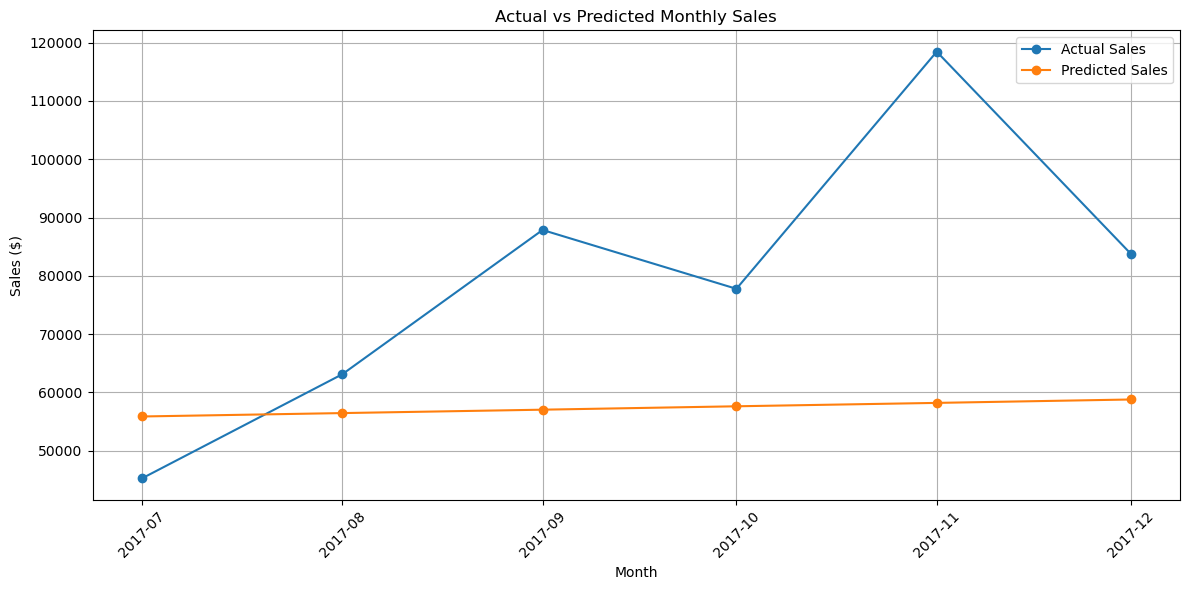

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales['Date'].iloc[-6:],
    y_test,
    marker='o',
    label='Actual Sales'
)

plt.plot(
    monthly_sales['Date'].iloc[-6:],
    y_pred,
    marker='o',
    label='Predicted Sales'
)

plt.title('Actual vs Predicted Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Sales ($)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
monthly_sales['Month'] = monthly_sales['Date'].dt.month

monthly_sales.head()

,Date,Sales,Month_Number,Month
0,2014-01-01,14236.895,0,1
1,2014-02-01,4519.892,1,2
2,2014-03-01,55691.009,2,3
3,2014-04-01,28295.345,3,4
4,2014-05-01,23648.287,4,5


In [23]:
monthly_pattern = monthly_sales.groupby('Month')['Sales'].mean()

print(monthly_pattern)

Month
1     23731.208900
2     14937.812850
3     51251.372200
4     34440.532150
5     38757.202925
6     38179.669825
7     36809.524250
8     39761.015750
9     76912.486425
10    50080.746175
11    88115.267750
12    81323.375875
Name: Sales, dtype: float64


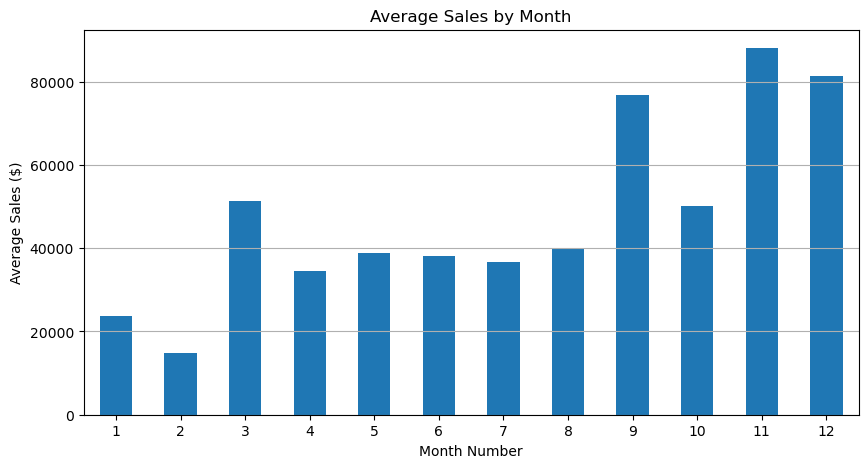

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

monthly_pattern.plot(kind='bar')

plt.title('Average Sales by Month')
plt.xlabel('Month Number')
plt.ylabel('Average Sales ($)')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [25]:
# Create month features
X = monthly_sales[['Month_Number', 'Month']]

# Target variable
y = monthly_sales['Sales']

# Split data into training and testing
X_train = X.iloc[:-6]
X_test = X.iloc[-6:]

y_train = y.iloc[:-6]
y_test = y.iloc[-6:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (42, 2)
Testing data: (6, 2)


In [26]:
from sklearn.linear_model import LinearRegression

# Create model
seasonal_model = LinearRegression()

# Train model
seasonal_model.fit(X_train, y_train)

print("Seasonal Machine Learning model trained successfully!")

Seasonal Machine Learning model trained successfully!


In [27]:
# Predict sales
seasonal_predictions = seasonal_model.predict(X_test)

print("Actual Sales:")
print(y_test.values)

print("\nPredicted Sales:")
print(seasonal_predictions.round(2))

Actual Sales:
[ 45264.416   63120.888   87866.652   77776.9232 118447.825   83829.3188]

Predicted Sales:
[58031.82 62815.2  67598.58 72381.96 77165.34 81948.72]


In [28]:
from sklearn.metrics import mean_absolute_error, r2_score

mae_new = mean_absolute_error(y_test, seasonal_predictions)
r2_new = r2_score(y_test, seasonal_predictions)

print("New Model Evaluation")
print("--------------------")
print("Mean Absolute Error:", round(mae_new, 2))
print("R2 Score:", round(r2_new, 3))

New Model Evaluation
--------------------
Mean Absolute Error: 13649.87
R2 Score: 0.242


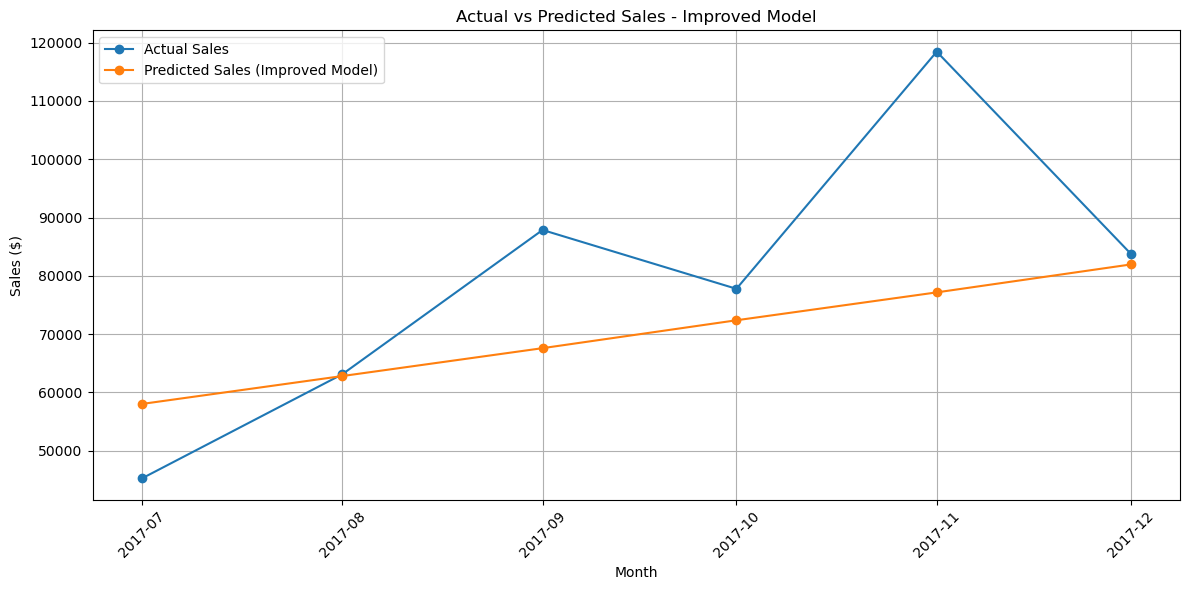

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales['Date'].iloc[-6:],
    y_test,
    marker='o',
    label='Actual Sales'
)

plt.plot(
    monthly_sales['Date'].iloc[-6:],
    seasonal_predictions,
    marker='o',
    label='Predicted Sales (Improved Model)'
)

plt.title('Actual vs Predicted Sales - Improved Model')
plt.xlabel('Month')
plt.ylabel('Sales ($)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()